In [ ]:
#imports
import os
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
#downloading the unrotated MNIST data and assigning them in to train/test dataframes
url = 'https://f000.backblazeb2.com/file/jeldridge-data/mnist.npz'
output_dir = './localstorage'
local_filepath = os.path.join(output_dir, 'mnist.npz')

if not os.path.exists(local_filepath):
    urllib.request.urlretrieve(url, local_filepath)

with np.load(local_filepath) as data:
    X_train = data['train'].T
    y_train = data['train_labels'].squeeze()
    X_test = data['test'].T
    y_test = data['test_labels'].squeeze()

#checking shape for unrotated inputs
print("Train images shape:", X_train.shape)
print("Train labels shape:", y_train.shape)
print("Test images shape:", X_test.shape)
print("Test labels shape:", y_test.shape)

In [11]:
import pandas as pd
import numpy as np

X_visp = pd.read_csv("/Users/audrey/Downloads/x_df1.csv").values
X_visal = pd.read_csv("/Users/audrey/Downloads/x_df2.csv").values

drifting_table = pd.read_csv("/Users/audrey/Downloads/drifting_table.csv")

grating_trials = drifting_table[
    drifting_table["orientation"].notna()
].reset_index(drop=True)

y = grating_trials["orientation"].values

print("VISp:", X_visp.shape)
print("VISal:", X_visal.shape)
print("y:", y.shape)
print("orientations:", np.unique(y))

VISp: (600, 88)
VISal: (600, 93)
y: (600,)
orientations: [  0.  45.  90. 135. 180. 225. 270. 315.]


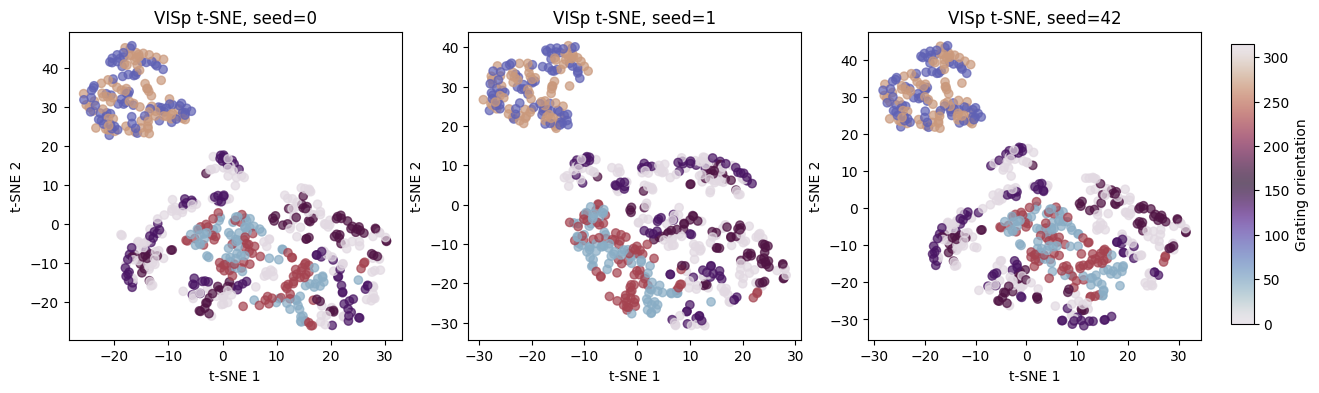

In [13]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import numpy as np

seeds = [0, 1, 42]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, seed in zip(axes, seeds):
    tsne = TSNE(
        n_components=2,
        perplexity=30,
        random_state=seed,
        init="pca",
        learning_rate="auto"
    )

    Z = tsne.fit_transform(X_visp)

    sc = ax.scatter(
        Z[:, 0],
        Z[:, 1],
        c=y,
        cmap="twilight",
        alpha=0.7
    )

    ax.set_title(f"VISp t-SNE, seed={seed}")
    ax.set_xlabel("t-SNE 1")
    ax.set_ylabel("t-SNE 2")

plt.subplots_adjust(right=0.88)

cbar_ax = fig.add_axes([0.90, 0.15, 0.015, 0.7])

fig.colorbar(
    sc,
    cax=cbar_ax,
    label="Grating orientation"
)

plt.show()

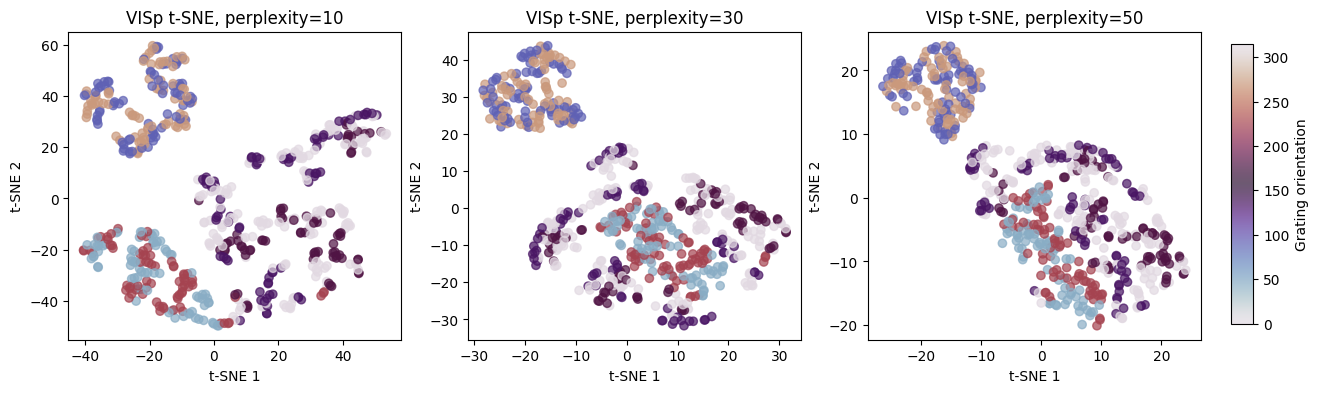

In [14]:
perplexities = [10, 30, 50]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, p in zip(axes, perplexities):
    tsne = TSNE(
        n_components=2,
        perplexity=p,
        random_state=42,
        init="pca",
        learning_rate="auto"
    )

    Z = tsne.fit_transform(X_visp)

    sc = ax.scatter(
        Z[:, 0],
        Z[:, 1],
        c=y,
        cmap="twilight",
        alpha=0.7
    )

    ax.set_title(f"VISp t-SNE, perplexity={p}")
    ax.set_xlabel("t-SNE 1")
    ax.set_ylabel("t-SNE 2")

plt.subplots_adjust(right=0.88)

cbar_ax = fig.add_axes([0.90, 0.15, 0.015, 0.7])

fig.colorbar(
    sc,
    cax=cbar_ax,
    label="Grating orientation"
)

plt.show()

/Users/audrey/Library/Python/3.9/lib/python/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/audrey/Library/Python/3.9/lib/python/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/audrey/Library/Python/3.9/lib/python/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


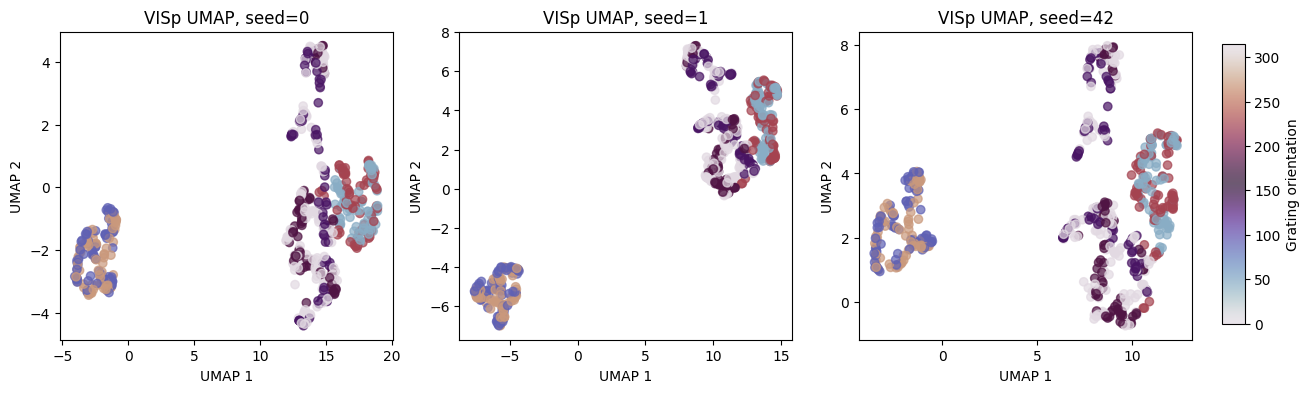

In [15]:
import umap.umap_ as umap

seeds = [0, 1, 42]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, seed in zip(axes, seeds):
    reducer = umap.UMAP(
        n_components=2,
        n_neighbors=15,
        min_dist=0.1,
        random_state=seed
    )

    Z = reducer.fit_transform(X_visp)

    sc = ax.scatter(
        Z[:, 0],
        Z[:, 1],
        c=y,
        cmap="twilight",
        alpha=0.7
    )

    ax.set_title(f"VISp UMAP, seed={seed}")
    ax.set_xlabel("UMAP 1")
    ax.set_ylabel("UMAP 2")

plt.subplots_adjust(right=0.88)

cbar_ax = fig.add_axes([0.90, 0.15, 0.015, 0.7])

fig.colorbar(
    sc,
    cax=cbar_ax,
    label="Grating orientation"
)

plt.show()

/Users/audrey/Library/Python/3.9/lib/python/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/audrey/Library/Python/3.9/lib/python/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/audrey/Library/Python/3.9/lib/python/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


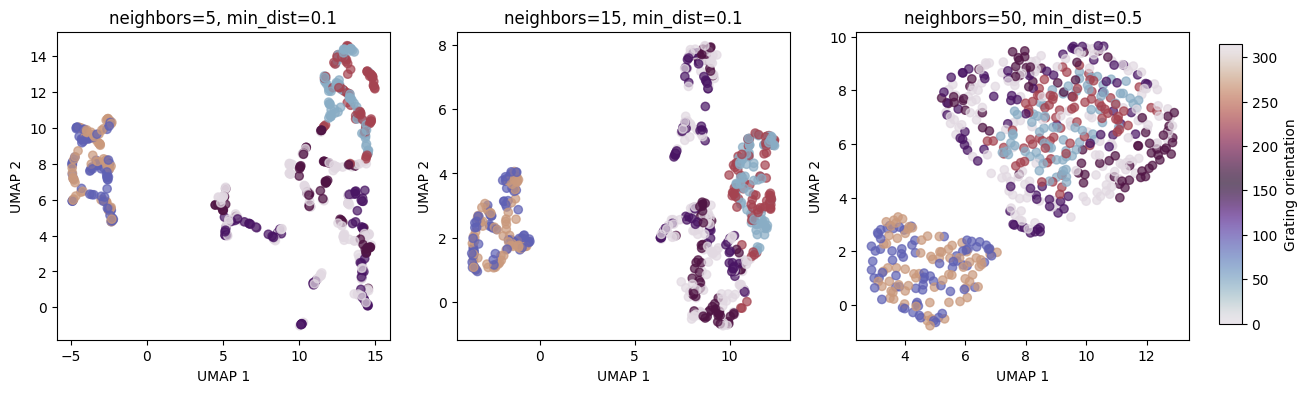

In [16]:
settings = [
    (5, 0.1),
    (15, 0.1),
    (50, 0.5)
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (n_neighbors, min_dist) in zip(axes, settings):
    reducer = umap.UMAP(
        n_components=2,
        n_neighbors=n_neighbors,
        min_dist=min_dist,
        random_state=42
    )

    Z = reducer.fit_transform(X_visp)

    sc = ax.scatter(
        Z[:, 0],
        Z[:, 1],
        c=y,
        cmap="twilight",
        alpha=0.7
    )

    ax.set_title(
        f"neighbors={n_neighbors}, min_dist={min_dist}"
    )

    ax.set_xlabel("UMAP 1")
    ax.set_ylabel("UMAP 2")

plt.subplots_adjust(right=0.88)

cbar_ax = fig.add_axes([0.90, 0.15, 0.015, 0.7])

fig.colorbar(
    sc,
    cax=cbar_ax,
    label="Grating orientation"
)

plt.show()

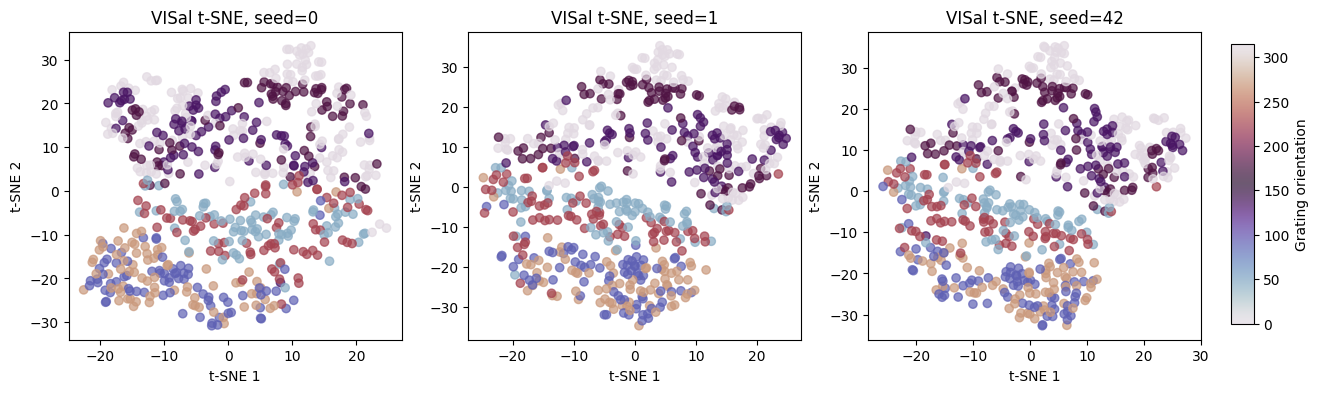

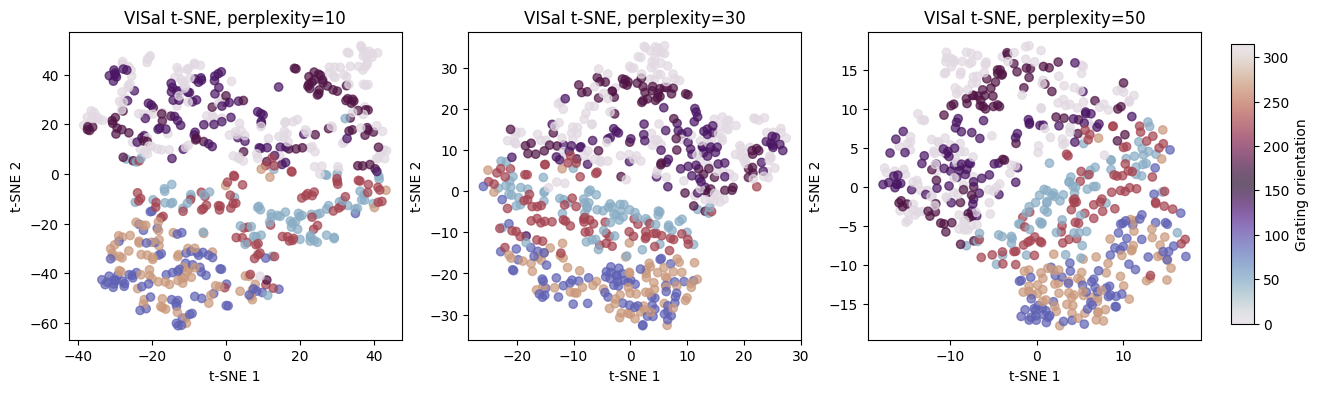

/Users/audrey/Library/Python/3.9/lib/python/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/audrey/Library/Python/3.9/lib/python/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/audrey/Library/Python/3.9/lib/python/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


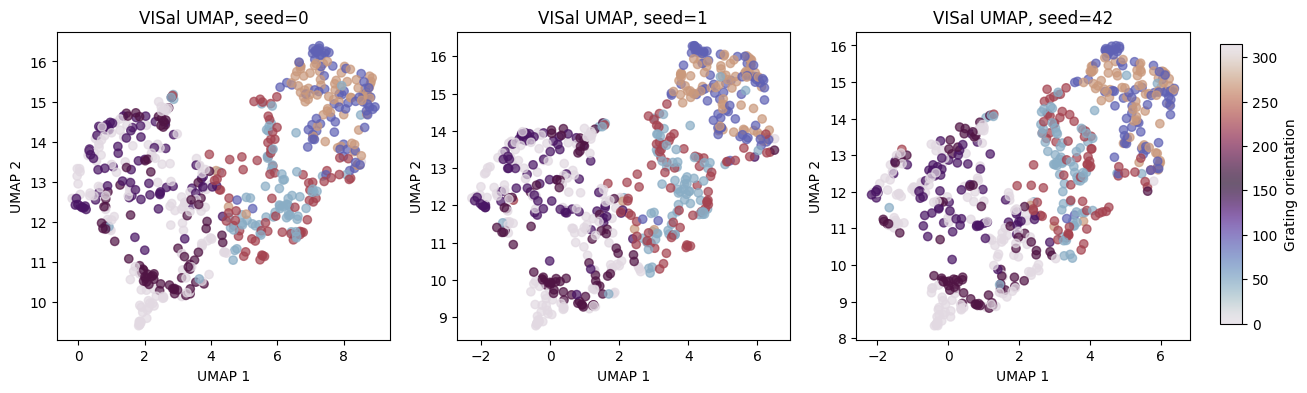

/Users/audrey/Library/Python/3.9/lib/python/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/audrey/Library/Python/3.9/lib/python/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/audrey/Library/Python/3.9/lib/python/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


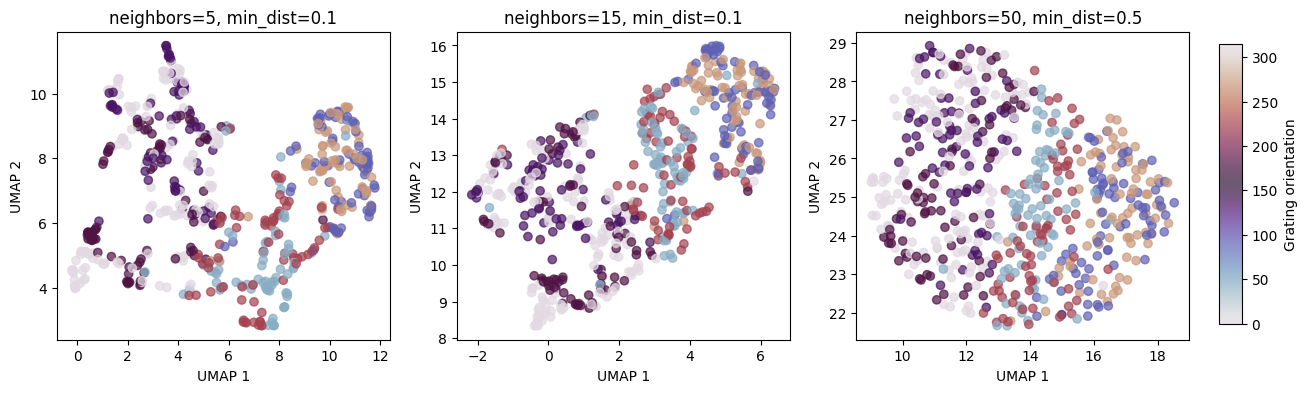

In [17]:
from sklearn.manifold import TSNE
import umap.umap_ as umap
import matplotlib.pyplot as plt
import numpy as np

# -----------------------------
# 1. t-SNE: different seeds
# -----------------------------
seeds = [0, 1, 42]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, seed in zip(axes, seeds):
    tsne = TSNE(
        n_components=2,
        perplexity=30,
        random_state=seed,
        init="pca",
        learning_rate="auto"
    )

    Z = tsne.fit_transform(X_visal)

    sc = ax.scatter(
        Z[:, 0],
        Z[:, 1],
        c=y,
        cmap="twilight",
        alpha=0.7
    )

    ax.set_title(f"VISal t-SNE, seed={seed}")
    ax.set_xlabel("t-SNE 1")
    ax.set_ylabel("t-SNE 2")

plt.subplots_adjust(right=0.88)
cbar_ax = fig.add_axes([0.90, 0.15, 0.015, 0.7])
fig.colorbar(sc, cax=cbar_ax, label="Grating orientation")
plt.show()


# -----------------------------
# 2. t-SNE: different perplexities
# -----------------------------
perplexities = [10, 30, 50]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, p in zip(axes, perplexities):
    tsne = TSNE(
        n_components=2,
        perplexity=p,
        random_state=42,
        init="pca",
        learning_rate="auto"
    )

    Z = tsne.fit_transform(X_visal)

    sc = ax.scatter(
        Z[:, 0],
        Z[:, 1],
        c=y,
        cmap="twilight",
        alpha=0.7
    )

    ax.set_title(f"VISal t-SNE, perplexity={p}")
    ax.set_xlabel("t-SNE 1")
    ax.set_ylabel("t-SNE 2")

plt.subplots_adjust(right=0.88)
cbar_ax = fig.add_axes([0.90, 0.15, 0.015, 0.7])
fig.colorbar(sc, cax=cbar_ax, label="Grating orientation")
plt.show()


# -----------------------------
# 3. UMAP: different seeds
# -----------------------------
seeds = [0, 1, 42]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, seed in zip(axes, seeds):
    reducer = umap.UMAP(
        n_components=2,
        n_neighbors=15,
        min_dist=0.1,
        random_state=seed
    )

    Z = reducer.fit_transform(X_visal)

    sc = ax.scatter(
        Z[:, 0],
        Z[:, 1],
        c=y,
        cmap="twilight",
        alpha=0.7
    )

    ax.set_title(f"VISal UMAP, seed={seed}")
    ax.set_xlabel("UMAP 1")
    ax.set_ylabel("UMAP 2")

plt.subplots_adjust(right=0.88)
cbar_ax = fig.add_axes([0.90, 0.15, 0.015, 0.7])
fig.colorbar(sc, cax=cbar_ax, label="Grating orientation")
plt.show()


# -----------------------------
# 4. UMAP: different parameters
# -----------------------------
settings = [
    (5, 0.1),
    (15, 0.1),
    (50, 0.5)
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (n_neighbors, min_dist) in zip(axes, settings):
    reducer = umap.UMAP(
        n_components=2,
        n_neighbors=n_neighbors,
        min_dist=min_dist,
        random_state=42
    )

    Z = reducer.fit_transform(X_visal)

    sc = ax.scatter(
        Z[:, 0],
        Z[:, 1],
        c=y,
        cmap="twilight",
        alpha=0.7
    )

    ax.set_title(
        f"neighbors={n_neighbors}, min_dist={min_dist}"
    )

    ax.set_xlabel("UMAP 1")
    ax.set_ylabel("UMAP 2")

plt.subplots_adjust(right=0.88)
cbar_ax = fig.add_axes([0.90, 0.15, 0.015, 0.7])
fig.colorbar(sc, cax=cbar_ax, label="Grating orientation")
plt.show()

In [19]:
%pip install torch

Defaulting to user installation because normal site-packages is not writeable
     |████████████████████████████████| 73.6 MB 816 kB/s eta 0:00:01
     |████████████████████████████████| 200 kB 10.7 MB/s eta 0:00:01
     |████████████████████████████████| 1.6 MB 10.2 MB/s eta 0:00:01
     |████████████████████████████████| 6.3 MB 13.8 MB/s eta 0:00:01
     |████████████████████████████████| 536 kB 9.6 MB/s eta 0:00:01
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [21]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import umap.umap_ as umap

from sklearn.metrics.pairwise import cosine_similarity
from scipy.stats import pearsonr

# Load VISp data
X_visp = pd.read_csv(
    "/Users/audrey/Downloads/x_df1.csv"
).values

drifting_table = pd.read_csv(
    "/Users/audrey/Downloads/drifting_table.csv"
)

# Remove blank presentations
grating_trials = drifting_table[
    drifting_table["orientation"].notna()
].reset_index(drop=True)

y = grating_trials["orientation"].values

print("VISp:", X_visp.shape)
print("Orientations:", y.shape)

# UMAP representation
umap_model = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    random_state=42
)

Z_umap = umap_model.fit_transform(X_visp)

print("UMAP representation:", Z_umap.shape)

VISp: (600, 88)
Orientations: (600,)


/Users/audrey/Library/Python/3.9/lib/python/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP representation: (600, 2)


In [22]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader

class Encoder(nn.Module):
    def __init__(self, input_dim, hidden_dim=400, latent_dim=2):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.fc_mu = nn.Linear(hidden_dim, latent_dim)
        self.fc_logvar = nn.Linear(hidden_dim, latent_dim)

    def forward(self, x):
        h = torch.relu(self.fc1(x))
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        return mu, logvar


class Decoder(nn.Module):
    def __init__(self, latent_dim, output_dim, hidden_dim=400, likelihood="gaussian"):
        super().__init__()
        self.likelihood = likelihood
        self.fc1 = nn.Linear(latent_dim, hidden_dim)
        self.fc2 = nn.Linear(hidden_dim, output_dim)

    def forward(self, z):
        h = torch.relu(self.fc1(z))
        out = self.fc2(h)

        if self.likelihood == "poisson":
            out = F.softplus(out)

        return out


class VAE(nn.Module):
    def __init__(self, input_dim, latent_dim=2, hidden_dim=400, likelihood="gaussian"):
        super().__init__()

        self.encoder = Encoder(
            input_dim=input_dim,
            hidden_dim=hidden_dim,
            latent_dim=latent_dim
        )

        self.decoder = Decoder(
            latent_dim=latent_dim,
            output_dim=input_dim,
            hidden_dim=hidden_dim,
            likelihood=likelihood
        )

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x):
        mu, logvar = self.encoder(x)
        z = self.reparameterize(mu, logvar)
        recon = self.decoder(z)
        return recon, mu, logvar


def vae_loss(recon, x, mu, logvar, likelihood):

    if likelihood == "gaussian":
        recon_loss = F.mse_loss(
            recon,
            x,
            reduction="sum"
        )

    elif likelihood == "poisson":
        recon_loss = F.poisson_nll_loss(
            recon,
            x,
            log_input=False,
            full=True,
            reduction="sum"
        )

    kl_loss = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    )

    return recon_loss + kl_loss


def run_VAE(
    X,
    likelihood,
    batch_size,
    n_epochs,
    learning_rate,
    latent_dim=2
):

    dataset = TensorDataset(X)

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=True
    )

    model = VAE(
        input_dim=X.shape[1],
        latent_dim=latent_dim,
        likelihood=likelihood
    ).to(X.device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    for epoch in range(n_epochs):

        model.train()
        total_loss = 0

        for (batch,) in loader:

            optimizer.zero_grad()

            recon, mu, logvar = model(batch)

            loss = vae_loss(
                recon,
                batch,
                mu,
                logvar,
                likelihood
            )

            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        if epoch % 25 == 0:
            print(
                f"Epoch {epoch}: "
                f"loss = {total_loss:.2f}"
            )

    return model

In [23]:
# Choose device
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Convert spike counts to tensor
X_counts = np.round(X_visp * 2).astype(int)

X_tensor = torch.tensor(
    X_counts,
    dtype=torch.float32
).to(device)

# Train 2D Poisson VAE
vae_poisson = run_VAE(
    X_tensor,
    likelihood="poisson",
    batch_size=64,
    n_epochs=256,
    learning_rate=1e-3,
    latent_dim=2
)

# Extract the 2D latent representation
vae_poisson.eval()

with torch.no_grad():
    mu, _ = vae_poisson.encoder(X_tensor)
    Z_vae = mu.cpu().numpy()

print("Poisson VAE representation:", Z_vae.shape)

Epoch 0: loss = 1068706.98
Epoch 25: loss = 220021.17
Epoch 50: loss = 194585.46
Epoch 75: loss = 179530.98
Epoch 100: loss = 173179.34
Epoch 125: loss = 167746.90
Epoch 150: loss = 162938.63
Epoch 175: loss = 158766.02
Epoch 200: loss = 155749.11
Epoch 225: loss = 153362.23
Epoch 250: loss = 151368.04
Poisson VAE representation: (600, 2)


Observed UMAP-VAE RSA correlation: -0.107798286
Pearson p-value: 0.0
Observed RSA correlation: -0.107798286
Chance mean: 0.0006865677604801022
Chance SD: 0.012583042546203151
Two-sided permutation p-value: 0.000999000999000999


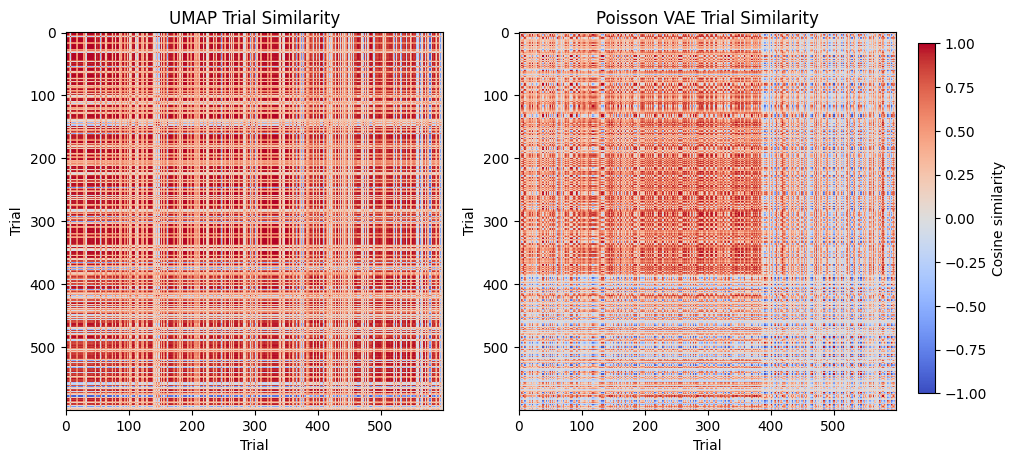

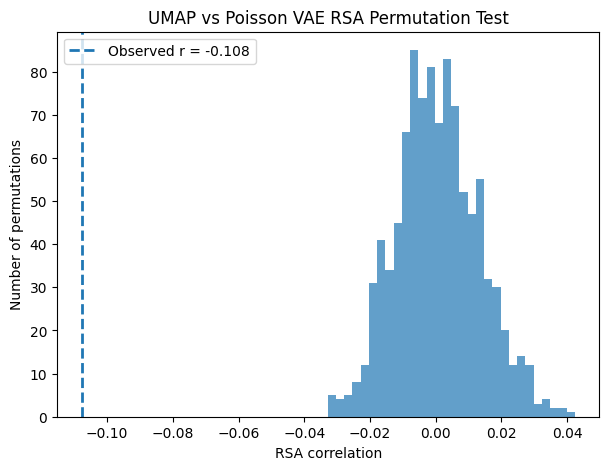

In [25]:
# --------------------------------
# RSA matrices
# --------------------------------

rsa_umap = cosine_similarity(Z_umap)
rsa_vae = cosine_similarity(Z_vae)

# Use only unique trial pairs
upper = np.triu_indices_from(rsa_umap, k=1)

observed_corr, pearson_p = pearsonr(
    rsa_umap[upper],
    rsa_vae[upper]
)

print("Observed UMAP-VAE RSA correlation:", observed_corr)
print("Pearson p-value:", pearson_p)


# --------------------------------
# Permutation test
# --------------------------------

n_permutations = 1000
permuted_corrs = np.zeros(n_permutations)

for i in range(n_permutations):

    perm = np.random.permutation(len(Z_vae))

    shuffled_vae = rsa_vae[
        np.ix_(perm, perm)
    ]

    permuted_corrs[i] = pearsonr(
        rsa_umap[upper],
        shuffled_vae[upper]
    )[0]

p_perm = (
    np.sum(np.abs(permuted_corrs) >= np.abs(observed_corr)) + 1
) / (n_permutations + 1)

print("Observed RSA correlation:", observed_corr)
print("Chance mean:", permuted_corrs.mean())
print("Chance SD:", permuted_corrs.std())
print("Two-sided permutation p-value:", p_perm)



# --------------------------------
# Plot RSA matrices
# --------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(11, 5)
)

im = axes[0].imshow(
    rsa_umap,
    vmin=-1,
    vmax=1,
    cmap="coolwarm"
)

axes[0].set_title("UMAP Trial Similarity")
axes[0].set_xlabel("Trial")
axes[0].set_ylabel("Trial")

axes[1].imshow(
    rsa_vae,
    vmin=-1,
    vmax=1,
    cmap="coolwarm"
)

axes[1].set_title("Poisson VAE Trial Similarity")
axes[1].set_xlabel("Trial")
axes[1].set_ylabel("Trial")

plt.subplots_adjust(right=0.88)

cbar_ax = fig.add_axes(
    [0.90, 0.15, 0.015, 0.7]
)

fig.colorbar(
    im,
    cax=cbar_ax,
    label="Cosine similarity"
)

plt.show()


# --------------------------------
# Plot null distribution
# --------------------------------

plt.figure(figsize=(7, 5))

plt.hist(
    permuted_corrs,
    bins=30,
    alpha=0.7
)

plt.axvline(
    observed_corr,
    linestyle="--",
    linewidth=2,
    label=f"Observed r = {observed_corr:.3f}"
)

plt.xlabel("RSA correlation")
plt.ylabel("Number of permutations")
plt.title("UMAP vs Poisson VAE RSA Permutation Test")
plt.legend()

plt.show()